# Adversarial Autoencoder (AAE) Encoder Training

Defines and trains an AAE encoder/decoder stack over the cleaned features. The AAE replaces the KL divergence term in the VAE with an adversarial loss: a discriminator tries to distinguish latent vectors from the encoder vs. samples from the prior (standard normal), while the encoder tries to fool the discriminator.

> Built on top of `02_encoder_training.ipynb` (VAE).

In [14]:
import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import plotly.express as px
%matplotlib inline

## Data Loading & Preprocessing

Same pipeline as the VAE notebook.

In [15]:
import ast

path = '../../data/processed/top500k_catalog.csv'
raw_df = pd.read_csv(path)
print(f"Raw CSV: {len(raw_df)} rows, {len(raw_df.columns)} columns")

# --- Standardise key to int 0-11 ---
NOTE_TO_INT = {
    'C': 0, 'C#': 1, 'Db': 1, 'D': 2, 'D#': 3, 'Eb': 3,
    'E': 4, 'F': 5, 'F#': 6, 'Gb': 6, 'G': 7, 'G#': 8,
    'Ab': 8, 'A': 9, 'A#': 10, 'Bb': 10, 'B': 11,
}

def parse_key(v):
    if pd.isna(v):
        return np.nan
    s = str(v).strip()
    if s in NOTE_TO_INT:
        return NOTE_TO_INT[s]
    try:
        return int(float(s))
    except ValueError:
        return np.nan

raw_df['key'] = raw_df['key'].apply(parse_key)

# --- Standardise mode to int 0/1 ---
MODE_MAP = {'major': 1, 'minor': 0, '1': 1, '0': 0, '1.0': 1, '0.0': 0}

def parse_mode(v):
    if pd.isna(v):
        return np.nan
    s = str(v).strip().lower()
    if s in MODE_MAP:
        return MODE_MAP[s]
    try:
        return int(float(s))
    except ValueError:
        return np.nan

raw_df['mode'] = raw_df['mode'].apply(parse_mode)

# --- Parse genre: extract first genre from stringified lists ---
def parse_genre(v):
    if pd.isna(v) or str(v).strip() == '':
        return np.nan
    s = str(v).strip()
    if s.startswith('['):
        try:
            items = ast.literal_eval(s)
            return items[0] if items else np.nan
        except (ValueError, SyntaxError):
            return s.strip("[]'\" ")
    return s

raw_df['genre'] = raw_df['genre'].apply(parse_genre)

# --- Drop rows missing genre, key, or mode ---
before = len(raw_df)
raw_df = raw_df.dropna(subset=['genre', 'key', 'mode'])
raw_df['key'] = raw_df['key'].astype(int)
raw_df['mode'] = raw_df['mode'].astype(int)
print(f"After dropping missing genre/key/mode: {len(raw_df)} rows ({before - len(raw_df)} dropped)")

# --- Drop genres with very few samples (< 50) so stratification works ---
genre_counts = raw_df['genre'].value_counts()
valid_genres = genre_counts[genre_counts >= 50].index
raw_df = raw_df[raw_df['genre'].isin(valid_genres)].reset_index(drop=True)
print(f"After dropping rare genres (< 50 samples): {len(raw_df)} rows, {raw_df['genre'].nunique()} genres")

# --- Select feature columns ---
AUDIO_FEATURES = [
    'danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
    'instrumentalness', 'liveness', 'valence', 'tempo', 'popularity',
]
songs_df = raw_df[AUDIO_FEATURES + ['key', 'mode', 'genre']].copy()
songs_df = songs_df.dropna().reset_index(drop=True)
print(f"Final dataset: {len(songs_df)} rows")

# --- Train / test split ---
X_train_embedding, X_test_embedding, y_train_embedding, y_test_embedding = train_test_split(
    songs_df.drop(columns=['genre']), songs_df['genre'],
    test_size=0.2, random_state=42, stratify=songs_df['genre']
)

ohe = OneHotEncoder()
scaler = StandardScaler()

X_train_embedding_num = X_train_embedding.drop(columns=['key', 'mode'])
X_test_embedding_num = X_test_embedding.drop(columns=['key', 'mode'])

train_key = ohe.fit_transform(X_train_embedding['key'].values.reshape(-1, 1)).toarray()
test_key = ohe.transform(X_test_embedding['key'].values.reshape(-1, 1)).toarray()
train_mode = X_train_embedding['mode'].values.reshape(-1, 1)
test_mode = X_test_embedding['mode'].values.reshape(-1, 1)

X_train_embedding_cat = np.concatenate((train_key, train_mode), axis=1)
X_test_embedding_cat = np.concatenate((test_key, test_mode), axis=1)

X_train_embedding_num = scaler.fit_transform(X_train_embedding_num)
X_test_embedding_num = scaler.transform(X_test_embedding_num)

X_train_embedding = np.concatenate((X_train_embedding_num, X_train_embedding_cat), axis=1)
X_test_embedding = np.concatenate((X_test_embedding_num, X_test_embedding_cat), axis=1)

# Encode genre labels for supervised classification loss
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train_embedding)
y_test_encoded = label_encoder.transform(y_test_embedding)
num_genres = len(label_encoder.classes_)

print(f"Train shape: {X_train_embedding.shape}, Test shape: {X_test_embedding.shape}")
print(f"Num genres: {num_genres}")
print(f"Genres: {list(label_encoder.classes_)}")

Raw CSV: 500000 rows, 21 columns
After dropping missing genre/key/mode: 294624 rows (205376 dropped)
After dropping rare genres (< 50 samples): 282667 rows, 370 genres
Final dataset: 282667 rows
Train shape: (226133, 23), Test shape: (56534, 23)
Num genres: 370
Genres: ['acoustic', 'adult_standards', 'afrobeat', 'alt-rock', 'alternative', 'alternative_hip_hop', 'alternative_metal', 'alternative_rock', 'ambient', 'anime', 'anime_rock', 'arabesk', 'arkansas_country', 'art_rock', 'australian_alternative_rock', 'australian_psych', 'australian_rock', 'autore",_', 'axe', 'bachata', 'bakersfield_sound', 'beatlesque', 'big_room', 'black-metal', 'black_metal', 'bluegrass', 'blues', 'blues_rock', 'bolero', 'bossa_nova', 'bow_pop', 'boy_band', 'brazil', 'brazilian_soul', 'breakbeat', 'brill_building_pop', 'british', 'british_blues', 'british_invasion', 'british_orchestra', 'britpop', 'brooklyn_drill', 'brostep', 'bubblegum_dance', 'bubblegum_pop', 'canadian_indie', 'canadian_metal', 'canadian_pop

## AAE Architecture

**Encoder & Decoder**: Same as VAE (input_dim -> 19 -> 15 -> latent_dim).

**Discriminator**: Takes latent vectors (real from prior N(0,I) or fake from encoder) and outputs probability of being real. Trained to distinguish; encoder is trained to fool it.

In [16]:
latent_dim = 12
input_dim = X_train_embedding.shape[1]

class MixtureGaussianPrior:
    """
    Mixture-of-Gaussians prior p(z) = sum_k pi_k N(mu_k, sigma^2 I)
    Designed to be smooth by using moderate mean spread (alpha) and
    sufficiently large sigma to create overlap (no big gaps).
    """
    def __init__(self, K, latent_dim, alpha=1.5, sigma=1.0, device="cpu", learnable_means=False):
        self.K = K
        self.latent_dim = latent_dim
        self.alpha = alpha
        self.sigma = sigma
        self.device = device

        # Initialize component means near the origin (controls separation)
        mus = torch.randn(K, latent_dim, device=device) * alpha  # spread controlled by alpha

        if learnable_means:
            self.mus = torch.nn.Parameter(mus)
        else:
            self.mus = mus  # fixed means

        # Uniform mixture weights (can change later)
        self.pi = torch.ones(K, device=device) / K

    def sample_conditional(self, y):
        mu = self.mus[y]  # (batch, latent_dim)
        eps = torch.randn_like(mu)
        return mu + self.sigma * eps

    def sample(self, batch_size):
        # Sample mixture component indices
        k = torch.multinomial(self.pi, batch_size, replacement=True)  # (batch,)
        mu = self.mus[k]  # (batch, latent_dim)
        eps = torch.randn(batch_size, self.latent_dim, device=self.device)
        z = mu + self.sigma * eps
        return z


def sampling(z_mean, z_log_var):
    """Reparameterization trick: z = z_mean + exp(z_log_var) * epsilon."""
    epsilon = torch.randn_like(z_mean)
    return z_mean + torch.exp(z_log_var) * epsilon


class Encoder(nn.Module):
    """input_dim -> 19 (ReLU) -> 15 (ReLU) -> z_mean, z_log_var"""

    def __init__(self, input_dim, latent_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 19)
        self.fc2 = nn.Linear(19, 15)
        self.z_mean = nn.Linear(15, latent_dim)
        self.z_log_var = nn.Linear(15, latent_dim)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.z_mean(x), self.z_log_var(x)


class Decoder(nn.Module):
    """latent_dim -> 15 (ReLU) -> 19 (ReLU) -> input_dim (tanh)"""

    def __init__(self, latent_dim, input_dim):
        super().__init__()
        self.fc1 = nn.Linear(latent_dim, 15)
        self.fc2 = nn.Linear(15, 19)
        self.out = nn.Linear(19, input_dim)

    def forward(self, z):
        x = F.relu(self.fc1(z))
        x = F.relu(self.fc2(x))
        return torch.tanh(self.out(x))


class Discriminator(nn.Module):
    """
    Discriminator for AAE: classifies latent vectors as real (from prior) or fake (from encoder).
    latent_dim -> 64 (LeakyReLU) -> 32 (LeakyReLU) -> 1 (sigmoid)
    """

    def __init__(self, latent_dim, hidden_dims=(64, 32)):
        super().__init__()
        layers = []
        prev = latent_dim
        for h in hidden_dims:
            layers.extend([nn.Linear(prev, h), nn.LeakyReLU(0.2)])
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        return torch.sigmoid(self.net(z))


class GenreClassifier(nn.Module):
    """Predicts genre from latent z. Used as auxiliary loss to improve clustering."""
    def __init__(self, latent_dim, num_genres):
        super().__init__()
        self.fc = nn.Linear(latent_dim, num_genres)

    def forward(self, z):
        return self.fc(z)


class AAE(nn.Module):
    """Adversarial Autoencoder: encoder + decoder (same forward as VAE)."""

    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, x):
        z_mean, z_log_var = self.encoder(x)
        z = sampling(z_mean, z_log_var)
        reconstruction = self.decoder(z)
        return reconstruction, z_mean, z_log_var, z

## Loss Functions & Training Steps

In [17]:
def reconstruction_loss(data, reconstruction):
    """MSE reconstruction loss (same as VAE)."""
    return F.mse_loss(reconstruction, data, reduction='sum') / data.size(0)


def train_reconstruction(aae, classifier, optimizer_ae, batch_x, batch_y, device, cls_weight=1.0):
    """Update encoder + decoder with reconstruction loss + genre classification loss."""
    aae.train()
    classifier.train()
    batch_x = batch_x.to(device)
    batch_y = batch_y.to(device).long()
    reconstruction, z_mean, z_log_var, z = aae(batch_x)
    recon_loss = reconstruction_loss(batch_x, reconstruction)
    logits = classifier(z)
    cls_loss = F.cross_entropy(logits, batch_y)
    total_loss = recon_loss + cls_weight * cls_loss
    optimizer_ae.zero_grad()
    total_loss.backward()
    optimizer_ae.step()
    return float(recon_loss.item()), float(cls_loss.item())


def train_discriminator(discriminator, optimizer_d, batch_z, batch_y, device, prior):
    discriminator.train()
    batch_y = batch_y.to(device).long()

    real_z = prior.sample_conditional(batch_y)    # <-- genre-conditioned real
    fake_z = batch_z.detach()

    real_pred = discriminator(real_z)
    fake_pred = discriminator(fake_z)

    loss_real = F.binary_cross_entropy(real_pred, torch.ones_like(real_pred))
    loss_fake = F.binary_cross_entropy(fake_pred, torch.zeros_like(fake_pred))
    d_loss = loss_real + loss_fake

    optimizer_d.zero_grad()
    d_loss.backward()
    optimizer_d.step()
    return float(d_loss.item())


def train_generator(aae, discriminator, optimizer_ae, batch_x, device):
    """Update encoder to fool discriminator: max log D(encoder(x))."""
    aae.train()
    discriminator.eval()  # Don't update discriminator
    batch_x = batch_x.to(device)

    _, _, _, z = aae(batch_x)
    pred = discriminator(z)

    # Generator wants D(z) to be 1 (fool discriminator)
    g_loss = F.binary_cross_entropy(pred, torch.ones_like(pred))

    optimizer_ae.zero_grad()
    g_loss.backward()
    optimizer_ae.step()
    return float(g_loss.item())

## Training Loop

Each epoch:
1. **Reconstruction phase**: Update encoder + decoder with reconstruction loss.
2. **Regularization phase**: Update discriminator, then update encoder (generator) to fool it.

In [18]:
device = "cuda" if torch.cuda.is_available() else "cpu"

encoder = Encoder(input_dim=input_dim, latent_dim=latent_dim)
decoder = Decoder(latent_dim=latent_dim, input_dim=input_dim)
discriminator = Discriminator(latent_dim=latent_dim)
classifier = GenreClassifier(latent_dim=latent_dim, num_genres=num_genres)
aae = AAE(encoder, decoder)

K = num_genres  # or choose 8, 10, 16, etc.
prior = MixtureGaussianPrior(
    K=K,
    latent_dim=latent_dim,
    alpha=1.5,      # controls cluster separation
    sigma=1.0,      # controls overlap/smoothness
    device=device,
    learnable_means=False
)

aae.to(device)
discriminator.to(device)
classifier.to(device)

X_train_tensor = torch.from_numpy(X_train_embedding).float()
y_train_tensor = torch.from_numpy(y_train_encoded).long()
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# AE optimizer: encoder + decoder + classifier (for reconstruction + classification)
optimizer_ae = torch.optim.Adam(
    list(encoder.parameters()) + list(decoder.parameters()) + list(classifier.parameters()),
    lr=1e-3
)
optimizer_d = torch.optim.Adam(discriminator.parameters(), lr=1e-3)

num_epochs = 100
cls_weight = 1.0  # Weight for genre classification loss
recon_losses = []
cls_losses = []
d_losses = []
g_losses = []

In [19]:
for epoch in range(num_epochs):
    epoch_recon = 0.0
    epoch_cls = 0.0
    epoch_d = 0.0
    epoch_g = 0.0
    count = 0

    for batch_x, batch_y in train_loader:
        batch_size = batch_x.size(0)

        # 1. Reconstruction phase (recon + genre classification)
        recon, cls = train_reconstruction(aae, classifier, optimizer_ae, batch_x, batch_y, device, cls_weight)
        epoch_recon += recon
        epoch_cls += cls

        # 2. Get latent z for discriminator
        with torch.no_grad():
            _, _, _, z = aae(batch_x.to(device))

        # 3. Discriminator phase
        d_loss = train_discriminator(discriminator, optimizer_d, z, batch_y, device, prior)
        ##d_loss = train_discriminator(discriminator, optimizer_d, z, batch_size, device)
        epoch_d += d_loss

        # 4. Generator (encoder) phase
        g_loss = train_generator(aae, discriminator, optimizer_ae, batch_x, device)
        epoch_g += g_loss

        count += 1

    n = len(train_loader)
    recon_losses.append(epoch_recon / n)
    cls_losses.append(epoch_cls / n)
    d_losses.append(epoch_d / n)
    g_losses.append(epoch_g / n)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:03d} | recon={recon_losses[-1]:.4f} | cls={cls_losses[-1]:.4f} | D={d_losses[-1]:.4f} | G={g_losses[-1]:.4f}")

Epoch 001 | recon=4.9844 | cls=4.5573 | D=1.1789 | G=1.0378
Epoch 010 | recon=2.9426 | cls=3.9998 | D=1.2528 | G=0.9133
Epoch 020 | recon=2.7833 | cls=4.0118 | D=1.2004 | G=1.0094
Epoch 030 | recon=2.7134 | cls=4.0082 | D=1.1512 | G=1.0687
Epoch 040 | recon=2.7046 | cls=4.0207 | D=1.1250 | G=1.1115
Epoch 050 | recon=2.7040 | cls=4.0213 | D=1.1155 | G=1.1143
Epoch 060 | recon=2.7162 | cls=4.0189 | D=1.0707 | G=1.1897
Epoch 070 | recon=2.5795 | cls=4.0228 | D=1.0947 | G=1.1544
Epoch 080 | recon=2.5667 | cls=4.0113 | D=1.0668 | G=1.1753
Epoch 090 | recon=2.5806 | cls=4.0077 | D=1.0817 | G=1.1690
Epoch 100 | recon=2.5391 | cls=3.9936 | D=1.0963 | G=1.1353


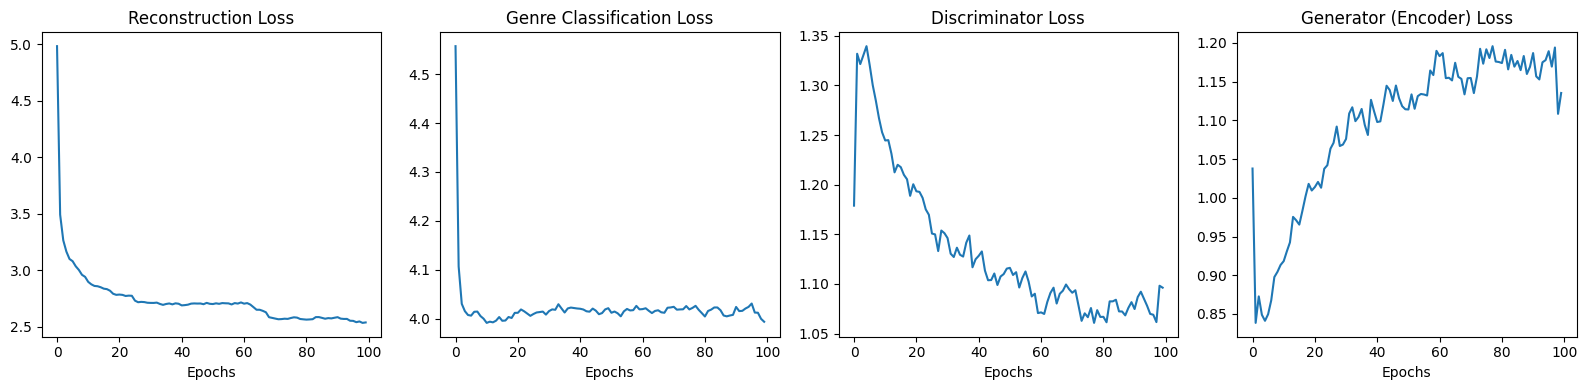

In [20]:
plt.figure(figsize=(16, 4))
plt.subplot(1, 4, 1)
plt.plot(recon_losses)
plt.title('Reconstruction Loss')
plt.xlabel('Epochs')

plt.subplot(1, 4, 2)
plt.plot(cls_losses)
plt.title('Genre Classification Loss')
plt.xlabel('Epochs')

plt.subplot(1, 4, 3)
plt.plot(d_losses)
plt.title('Discriminator Loss')
plt.xlabel('Epochs')

plt.subplot(1, 4, 4)
plt.plot(g_losses)
plt.title('Generator (Encoder) Loss')
plt.xlabel('Epochs')
plt.tight_layout()
plt.show()

In [21]:
import torch
# Trying to visualize latent space using UMAP
#from umap import UMAP

encoder.eval()
with torch.no_grad():
    X_train_tensor = torch.from_numpy(X_train_embedding).float().to(device)
    z_mean, z_log_var = encoder(X_train_tensor)
    latent_space = z_mean.cpu().numpy()

#umap = UMAP(n_neighbors=20, min_dist=0.1, random_state=42)
#z_umap = umap.fit_transform(latent_space)

#df_umap = pd.DataFrame({
#    "u0": z_umap[:, 0],
#    "u1": z_umap[:, 1],
#    "genre_group": y_train_embedding
#})
#fig = px.scatter(df_umap, x="u0", y="u1", color="genre_group", title="UMAP Latent Space")
#fig.show()

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(latent_space)

# Convert the data to a pandas DataFrame
df = pd.DataFrame({
    'pca0': X_train_pca[:, 0],
    'pca1': X_train_pca[:, 1],
    'genre_group': y_train_embedding
})

#Original code line: df = pd.DataFrame({'pca0': X_train_pca[:, 0], 'pca1': X_train_pca[:, 1], 'genre_group': y_train_embedding})

# Create a scatter plot using Plotly
fig = px.scatter(df, x='pca0', y='pca1', color='genre_group')

# Add labels and adjust the layout
fig.update_layout(
    title='PCA Latent Space Visualization',
    xaxis_title='pca0',
    yaxis_title='pca1',
    legend_title='Genre Group'
)

# Display the plot
fig.show()

## Save Model

In [22]:
os.makedirs('../checkpoints', exist_ok=True)

# Encode ALL songs (not just the training split) so the saved latent space
# covers the full catalog for nearest-neighbor lookup at serving time.
# Reuse songs_df which was already cleaned in the preprocessing cell.
X_full = songs_df.drop(columns=['genre'])
X_full_num = scaler.transform(X_full.drop(columns=['key', 'mode']))
full_key = ohe.transform(X_full['key'].values.reshape(-1, 1)).toarray()
full_mode = X_full['mode'].values.reshape(-1, 1)
X_full_processed = np.concatenate((X_full_num, np.concatenate((full_key, full_mode), axis=1)), axis=1).astype(np.float32)

encoder.eval()
with torch.no_grad():
    z_mean_full, _ = encoder(torch.from_numpy(X_full_processed).to(device))
    latent_space_full = z_mean_full.cpu().numpy()

torch.save({
    'encoder': encoder.state_dict(),
    'decoder': decoder.state_dict(),
    'discriminator': discriminator.state_dict(),
    'classifier': classifier.state_dict(),
    'scaler': scaler,
    'ohe': ohe,
    'label_encoder': label_encoder,
    'input_dim': input_dim,
    'latent_dim': latent_dim,
    'num_genres': num_genres,
    'latent_space': latent_space_full,
    'genre_groups': songs_df['genre'].values,
}, '../checkpoints/aae_encoder_500k.pt')
print(f'Saved to Model/checkpoints/aae_encoder.pt  --  latent space shape: {latent_space_full.shape}')

Saved to Model/checkpoints/aae_encoder.pt  --  latent space shape: (282667, 12)
